<a href="https://colab.research.google.com/github/Elder-stack/LHUD-Capstone-Ivan/blob/main/RealEstateAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the four CSV files
df_2000 = pd.read_csv('https://raw.githubusercontent.com/Elder-stack/LHUD-Capstone-Ivan/refs/heads/main/resale-flat-prices-based-on-approval-date-2000-feb-2012.csv')
df_2012 = pd.read_csv('https://raw.githubusercontent.com/Elder-stack/LHUD-Capstone-Ivan/refs/heads/main/resale-flat-prices-based-on-registration-date-from-mar-2012-to-dec-2014.csv')
df_2015 = pd.read_csv('https://raw.githubusercontent.com/Elder-stack/LHUD-Capstone-Ivan/refs/heads/main/resale-flat-prices-based-on-registration-date-from-jan-2015-to-dec-2016.csv')
df_2017 = pd.read_csv('https://raw.githubusercontent.com/Elder-stack/LHUD-Capstone-Ivan/refs/heads/main/ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv')

# 2. Combine all dataframes into one master dataset
df_master = pd.concat([df_2000, df_2012, df_2015, df_2017], ignore_index=True)

print(f"Master Dataset Shape: {df_master.shape}")
print(df_master.head())

Master Dataset Shape: (555658, 11)
     month        town flat_type block       street_name storey_range  \
0  2000-01  ANG MO KIO    3 ROOM   170  ANG MO KIO AVE 4     07 TO 09   
1  2000-01  ANG MO KIO    3 ROOM   174  ANG MO KIO AVE 4     04 TO 06   
2  2000-01  ANG MO KIO    3 ROOM   216  ANG MO KIO AVE 1     07 TO 09   
3  2000-01  ANG MO KIO    3 ROOM   215  ANG MO KIO AVE 1     07 TO 09   
4  2000-01  ANG MO KIO    3 ROOM   218  ANG MO KIO AVE 1     07 TO 09   

   floor_area_sqm      flat_model  lease_commence_date  resale_price  \
0            69.0        Improved                 1986      147000.0   
1            61.0        Improved                 1986      144000.0   
2            73.0  New Generation                 1976      159000.0   
3            73.0  New Generation                 1976      167000.0   
4            67.0  New Generation                 1976      163000.0   

  remaining_lease  
0             NaN  
1             NaN  
2             NaN  
3            

In [3]:
# Convert month to datetime and extract transaction year
df_master['transaction_date'] = pd.to_datetime(df_master['month'])
df_master['year'] = df_master['transaction_date'].dt.year

# Ensure numeric columns are properly formatted
numeric_cols = ['floor_area_sqm', 'resale_price', 'lease_commence_date']
for col in numeric_cols:
    if col in df_master.columns:
        df_master[col] = pd.to_numeric(df_master[col], errors='coerce')

# Handle remaining lease for 2017+ data if needed (extracting decimal years from strings)
def parse_remaining_lease(val):
    if pd.isna(val):
        return None
    if isinstance(val, (int, float)):
        return float(val)
    # If string like "61 years 04 months"
    parts = str(val).split()
    years = float(parts[0]) if len(parts) > 0 and parts[0].isdigit() else 0.0
    months = float(parts[2]) if len(parts) > 2 and parts[2].isdigit() else 0.0
    return years + (months / 12.0)

if 'remaining_lease' in df_master.columns:
    df_master['remaining_lease_years'] = df_master['remaining_lease'].apply(parse_remaining_lease)
else:
    # Approximate remaining lease if missing in older files
    df_master['remaining_lease_years'] = 99 - (df_master['year'] - df_master['lease_commence_date'])

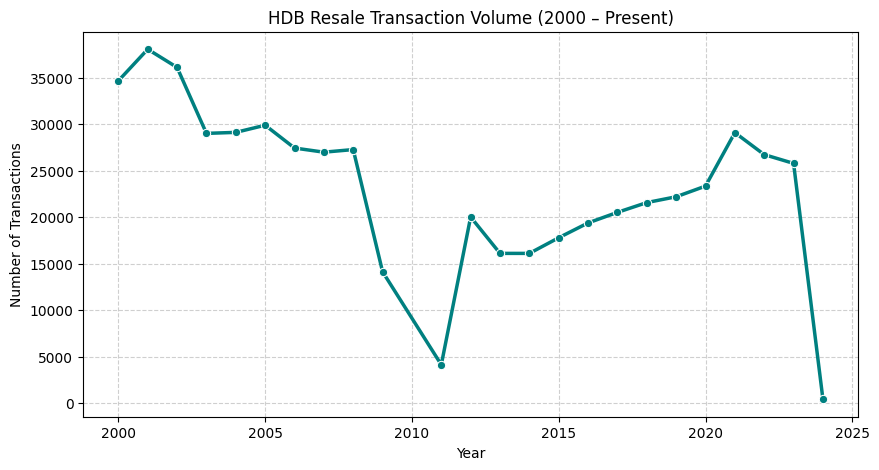

In [4]:
# Aggregate transaction count by year
demand_trend = df_master.groupby('year').size().reset_index(name='transaction_count')

plt.figure(figsize=(10, 5))
sns.lineplot(data=demand_trend, x='year', y='transaction_count', marker='o', color='teal', linewidth=2.5)
plt.title('HDB Resale Transaction Volume (2000 – Present)')
plt.xlabel('Year')
plt.ylabel('Number of Transactions')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

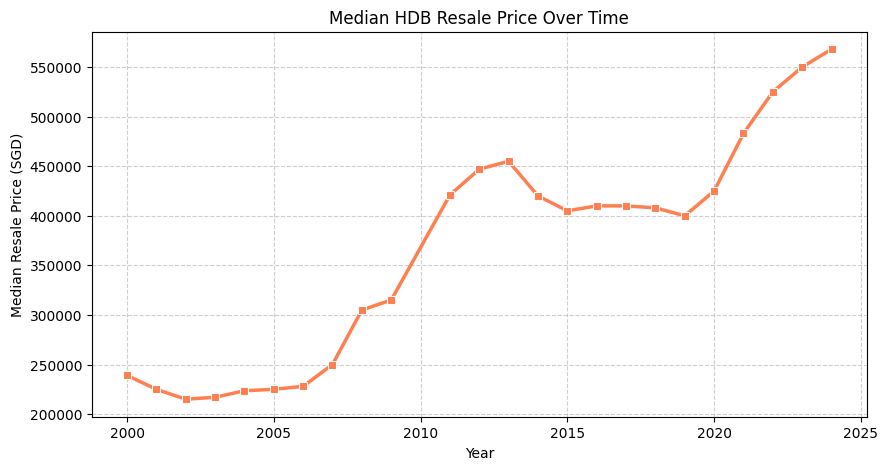

In [5]:
# Calculate median resale price and floor area price per sqm by year
price_trend = df_master.groupby('year')['resale_price'].agg(['median', 'mean']).reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=price_trend, x='year', y='median', marker='s', color='coral', linewidth=2.5)
plt.title('Median HDB Resale Price Over Time')
plt.xlabel('Year')
plt.ylabel('Median Resale Price (SGD)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

/tmp/ipykernel_1905/2831329040.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_master, x='flat_type', y='resale_price', palette='Set2')


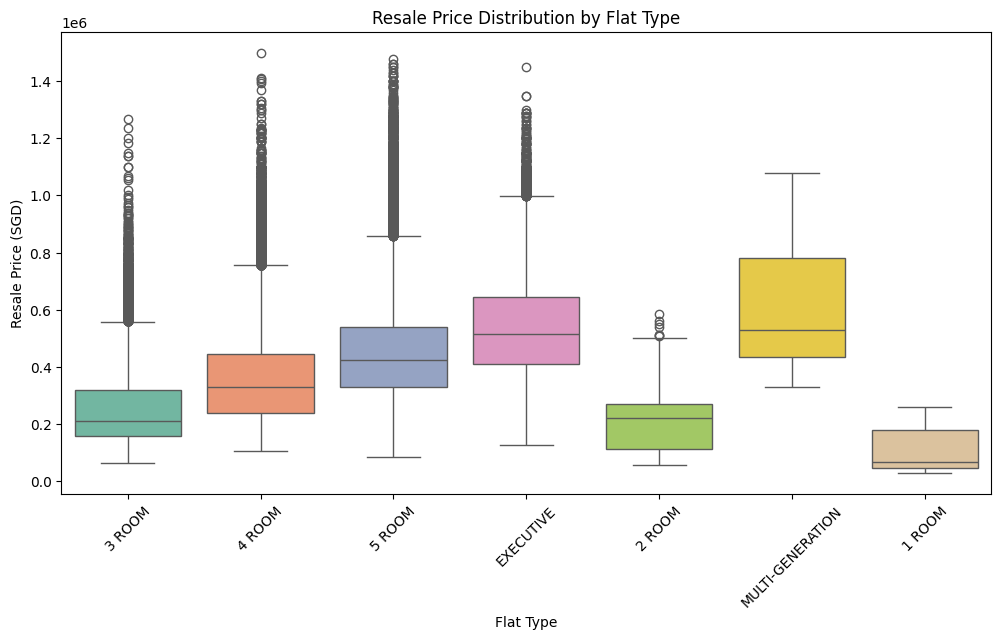

In [6]:
# Compare resale price distribution across flat types
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_master, x='flat_type', y='resale_price', palette='Set2')
plt.title('Resale Price Distribution by Flat Type')
plt.xlabel('Flat Type')
plt.ylabel('Resale Price (SGD)')
plt.xticks(rotation=45)
plt.show()

In [7]:
# Find top towns by average resale price and transaction volume
town_performance = df_master.groupby('town').agg(
    avg_price=('resale_price', 'mean'),
    total_transactions=('town', 'count')
).reset_index().sort_values(by='avg_price', ascending=False)

print("Top 10 Towns by Average Resale Price:")
print(town_performance.head(10))

Top 10 Towns by Average Resale Price:
               town      avg_price  total_transactions
6       BUKIT TIMAH  515993.466580                1380
17          PUNGGOL  483904.359654               17821
2            BISHAN  468059.638725               11290
7      CENTRAL AREA  447117.767429                4060
20         SENGKANG  437032.235725               27266
4       BUKIT MERAH  423403.518978               20618
16        PASIR RIS  415614.664740               19419
15    MARINE PARADE  406529.635231                4093
14  KALLANG/WHAMPOA  382723.751695               15967
18       QUEENSTOWN  378956.242554               16596
